> Notebook-friendly copy of `part-I/1.8-statistical-foundations-and-ml.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# 1.8) Statistical Foundations and the Machine-Learning Stepping-Stone

This subchapter fits models with scikit-learn and then plots data with seaborn. Regression recovers the environmental lapse rate from synthetic station data and scores it on held-out points; clustering and classification then use real Palmer Archipelago penguin measurements, where k-means groups birds without labels and logistic regression separates two species by bill shape. The seaborn half covers distributions, facets, categories and correlations. The generated code at the end scores a model on its own training data: it reports a near-perfect fit for a model that predicts new points badly.

**🎯 Learning objectives**

- Use the scikit-learn estimator interface: instantiate, fit, predict, with the X/y convention, across its three pillars — regression, clustering, and classification.
- Fit a linear regression for the lapse rate, split data into train and test sets, evaluate with RMSE and $R^2$, and recognise overfitting.
- Group unlabelled observations with `KMeans`, choose k with the elbow method and the silhouette plot, and summarise correlated features with `PCA`, reading each component as a direction in feature space.
- Standardise features with `StandardScaler` fitted on the training set only, fit a linear classifier (`LogisticRegression`), and read its weights and decision boundary.
- Explore data with seaborn, a layer over matplotlib: histograms and KDEs split by `hue=`, joint distributions, and regression plots.
- Know where a KDE misleads: bounded data and the choice of smoothing.
- Compare groups with faceted histograms, box plots, count and bar plots, and summarise tables and correlations as heat maps.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/scikit_learn_logo.svg" alt="The scikit-learn project logo" width="400">

<em>The scikit-learn logo, from the project's own <a href="https://github.com/scikit-learn/scikit-learn/blob/main/doc/logos/scikit-learn-logo.svg">repository</a>, BSD-3-Clause licensed.</em>

## 1.8.1 Statistical Modelling with scikit-learn

[scikit-learn](https://scikit-learn.org/stable/) covers three pillars of statistical modelling, and this section touches all three: *regression*, which learns the relationship between continuous inputs (predictors, or features) and a continuous output (the predictand, or target); *clustering*, which groups observations that resemble each other without being told what the groups are; and *classification*, which learns which of a set of classes an observation belongs to.

### Linear Regression

Linear regression is the simplest regression model. Given measurements of how one physical property $y$ depends on another, $x$, it predicts $\hat{y} = wx + b$, with slope $w$ and intercept $b$ chosen to fit the data.

The data here are synthetic: a set of stations whose air temperature falls with elevation at the environmental lapse rate of −6.5 °C km⁻¹, plus noise, so that the relationship the regression should recover is known exactly.

In [2]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
n = 80
elevation_m = rng.uniform(200, 3500, n)
temp_celsius = 15.0 - 6.5 * (elevation_m / 1000) + rng.normal(0, 1.5, n)
df = pd.DataFrame({"elevation_m": elevation_m, "temp_celsius": temp_celsius})
print(df.describe().round(2))

       elevation_m  temp_celsius
count        80.00         80.00
mean       1894.42          2.67
std         978.78          6.68
min         209.04         -9.87
25%        1161.85         -2.89
50%        1960.25          2.51
75%        2655.25          8.02
max        3490.79         16.17


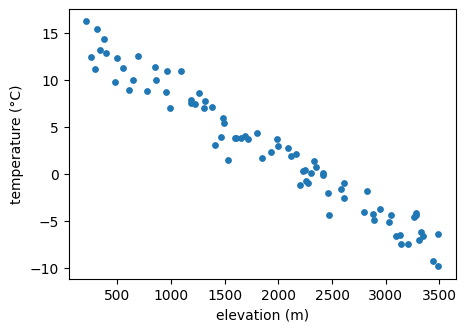

In [3]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(df["elevation_m"], df["temp_celsius"], s=15)
ax.set_xlabel("elevation (m)")
ax.set_ylabel("temperature (°C)")
plt.show()

Can the lapse rate be found from these points alone? Every scikit-learn model is an object used the same way: instantiate it, `fit` it to a feature matrix `X` and target vector `y`, then `predict`. By convention `X` is two-dimensional with shape (n_samples, n_features) and `y` is one-dimensional. The fitted parameters are stored on attributes ending in an underscore.

For a straight line $\hat{y} = wx + b$, `fit` chooses the slope $w$ and intercept $b$ that minimise the sum of squared errors

$$J(w, b) = \sum_{i=1}^{N}\left(y_i - \hat{y}_i\right)^2,$$

solved directly rather than by trial and error. Least squares picks the line with the smallest summed squared vertical distance to the points.

In [4]:
from sklearn.linear_model import LinearRegression

X = df[["elevation_m"]]     # 2D feature matrix (note the double brackets)
y = df["temp_celsius"]      # 1D target

model = LinearRegression()   # instantiate: an unfitted object
model.fit(X, y)                # fit: learn slope and intercept from the data
lapse_rate_celsius_km = model.coef_[0] * 1000          # °C per km
print("recovered lapse rate:", round(lapse_rate_celsius_km, 2), "°C km^-1")
print("intercept (sea-level temp):", round(model.intercept_, 2), "°C")
print("prediction at 2000 m:", round(model.predict(pd.DataFrame({"elevation_m": [2000]}))[0], 2), "°C")

recovered lapse rate: -6.67 °C km^-1
intercept (sea-level temp): 15.31 °C
prediction at 2000 m: 1.96 °C


**ℹ️ `X` must be two-dimensional**

`fit` expects `X` with shape (n_samples, n_features), even when there is a single feature. A pandas selection with double brackets, `df[["elevation_m"]]`, already has that shape. A one-dimensional numpy array does not, and `fit` raises `ValueError: Expected 2D array, got 1D array instead`. The fix is the `.reshape(-1, 1)` of the numpy section (1.3): it turns the array into one column, with `-1` telling numpy to work out the number of rows.

In [5]:
elevation_array = df["elevation_m"].values       # a numpy array of shape (80,)
print(elevation_array.shape, "->", elevation_array.reshape(-1, 1).shape)

model_array = LinearRegression().fit(elevation_array.reshape(-1, 1), y)
print("lapse rate from the array:", round(model_array.coef_[0] * 1000, 2), "°C km^-1")

(80,) -> (80, 1)
lapse rate from the array: -6.67 °C km^-1


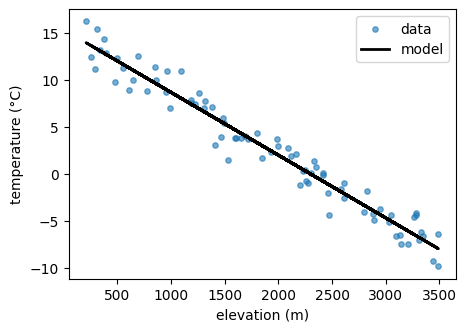

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(df["elevation_m"], df["temp_celsius"], s=15, alpha=0.6, label="data")
ax.plot(df["elevation_m"], model.predict(X), color="k", linewidth=2, label="model")
ax.set_xlabel("elevation (m)")
ax.set_ylabel("temperature (°C)")
ax.legend()
plt.show()

The recovered lapse rate is close to the −6.5 °C km⁻¹ built into the data, but not exact: 80
noisy stations only pin it down so far. More data narrows the gap. Each row below draws a fresh sample, so its 80-station value differs from the fit above.

In [7]:
for n_stations in (80, 800, 8000):
    elev_m = rng.uniform(200, 3500, n_stations)
    temp_celsius = 15.0 - 6.5 * (elev_m / 1000) + rng.normal(0, 1.5, n_stations)
    fitted = LinearRegression().fit(elev_m.reshape(-1, 1), temp_celsius)
    print(f"{n_stations:5d} stations -> lapse rate {fitted.coef_[0] * 1000:6.2f} °C km^-1, "
          f"intercept {fitted.intercept_:5.2f} °C")

   80 stations -> lapse rate  -6.65 °C km^-1, intercept 15.04 °C
  800 stations -> lapse rate  -6.54 °C km^-1, intercept 15.08 °C
 8000 stations -> lapse rate  -6.52 °C km^-1, intercept 15.04 °C


#### How the fit works, and how it is scored

`fit` has one criterion: the line that makes the squared vertical errors, called *residuals*, as small as possible. Both scores are built from residuals, so one picture shows what `fit` minimises, what the RMSE measures, and what $R^2$ compares against. It uses 15 of the stations so that the segments can be counted.

- **Left panel.** Each red segment is a residual $y_i - \hat{y}_i$: the gap between a station's measured temperature and the line's prediction at its elevation. `fit` picks the line that minimises the sum of the squared segment lengths. The root-mean-square error (RMSE) is $\sqrt{\tfrac{1}{N}\sum_i (y_i - \hat{y}_i)^2}$, the typical segment length, in °C.
- **Right panel.** A model that ignores elevation can only predict the mean temperature (dashed line). Its residuals are the orange segments. $R^2 = 1 - \mathrm{SS}_\text{res} / \mathrm{SS}_\text{tot}$, where $\mathrm{SS}_\text{res}$ is the sum of the squared red segments and $\mathrm{SS}_\text{tot}$ the sum of the squared orange ones. $R^2$ is the fraction of the orange error that the line removes: 1 when no residual is left, 0 when the line does no better than the mean, and negative when it does worse.

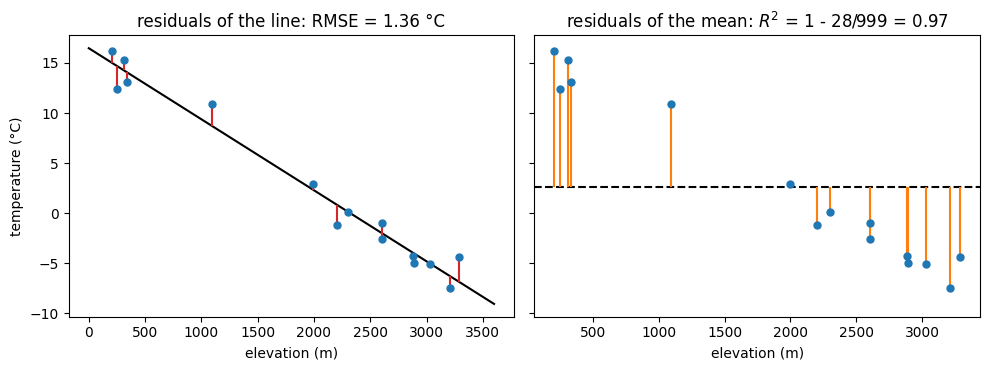

In [8]:
# the first 15 stations, refitted on their own
x_few = df["elevation_m"].values[:15]
y_few = df["temp_celsius"].values[:15]
fit_few = LinearRegression().fit(x_few.reshape(-1, 1), y_few)
y_line = fit_few.predict(x_few.reshape(-1, 1))

ss_res = np.sum((y_few - y_line) ** 2)             # squared residuals of the line
ss_tot = np.sum((y_few - np.mean(y_few)) ** 2)     # squared residuals of the mean
rmse = np.sqrt(np.mean((y_few - y_line) ** 2))
r2 = 1 - ss_res / ss_tot

elev_grid = np.linspace(0, 3600, 50)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax in axes:
    ax.scatter(x_few, y_few, s=25, zorder=3)
    ax.set_xlabel("elevation (m)")
axes[0].plot(elev_grid, fit_few.predict(elev_grid.reshape(-1, 1)), color="k")
axes[0].vlines(x_few, y_few, y_line, color="tab:red")        # one vertical segment per station
axes[0].set_title(f"residuals of the line: RMSE = {rmse:.2f} °C")
axes[0].set_ylabel("temperature (°C)")
axes[1].axhline(np.mean(y_few), color="k", linestyle="--")
axes[1].vlines(x_few, y_few, np.mean(y_few), color="tab:orange")
axes[1].set_title(f"residuals of the mean: $R^2$ = 1 - {ss_res:.0f}/{ss_tot:.0f} = {r2:.2f}")
plt.tight_layout()
plt.show()

#### Evaluating on held-out data

A model must be judged on data it has not seen. `train_test_split` holds out a test set, and the RMSE and $R^2$ defined above are then computed on those held-out points only.

test RMSE: 1.595 °C
test R^2:  0.947


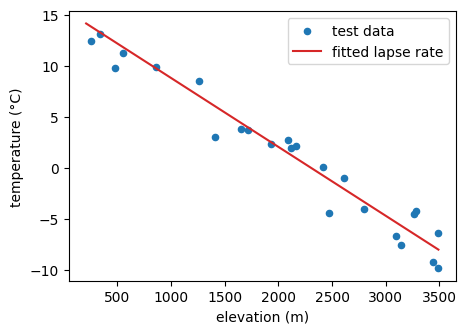

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

print("test RMSE:", round(root_mean_squared_error(y_test, y_pred), 3), "°C")
print("test R^2: ", round(r2_score(y_test, y_pred), 3))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(X_test["elevation_m"], y_test, s=20, label="test data")
grid = pd.DataFrame({"elevation_m": np.linspace(X["elevation_m"].min(), X["elevation_m"].max(), 100)})
ax.plot(grid["elevation_m"], model.predict(grid), color="tab:red", label="fitted lapse rate")
ax.set_xlabel("elevation (m)")
ax.set_ylabel("temperature (°C)")
ax.legend()
plt.show()

**🧠 Computational-thinking fundamental: evaluate on data the model has not seen**

The goal of a model is to generalise, so its performance is what it achieves on unseen data — never on the data it was fitted to. A sufficiently flexible model can fit any training set perfectly, including its noise, while predicting new points badly. The train/test split (and, better, cross-validation) exists to measure generalisation rather than memorisation. A model scored only on its training data can report an $R^2$ near 1.0 and still be badly wrong on the very next new point it sees.

### Clustering

Regression finds a relationship between inputs and a known output. Some questions have no output to learn: given many unlabelled measurements, which observations belong together? Clustering answers that, and a clustering can help interpret a complex, high-dimensional dataset. scikit-learn implements [many clustering algorithms](https://scikit-learn.org/stable/modules/clustering.html); this section uses the most common one.

#### k-means clustering

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/kmeans-expectation-maximization.png" alt="Four panels showing successive k-means iterations, the cluster centres moving and the point colours settling as the algorithm converges" width="100%">

<em>Four successive iterations of k-means on the same points. Each panel assigns every point to its
nearest centre and then moves each centre to the mean of the points assigned to it; by the fourth
panel neither step changes anything and the algorithm has converged. Figure from Jake VanderPlas,
<a href="https://github.com/jakevdp/PythonDataScienceHandbook">Python Data Science Handbook</a>
(code MIT-licensed).</em>

`KMeans` partitions points into `n_clusters` groups by repeatedly assigning each point to the
nearest centroid and moving each centroid to the mean of its group. It is easiest to see on data
built to have clusters: `make_blobs` draws points around a chosen number of centres, and the
fitted centroids land on them.

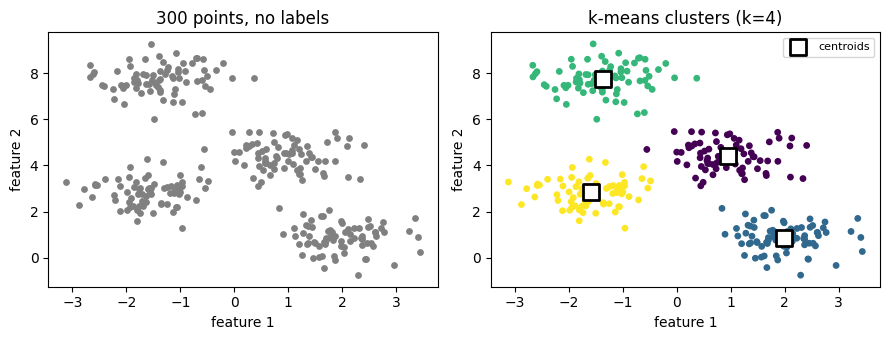

In [10]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

X_blobs, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)
km_blobs = KMeans(n_clusters=4, random_state=0, n_init=10).fit(X_blobs)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].scatter(X_blobs[:, 0], X_blobs[:, 1], s=15, color="0.5")
axes[0].set_title("300 points, no labels")

axes[1].scatter(X_blobs[:, 0], X_blobs[:, 1], c=km_blobs.labels_, s=15, cmap="viridis")
axes[1].scatter(*km_blobs.cluster_centers_.T, marker="s", s=140, c="white",
                edgecolors="k", linewidths=2, label="centroids")
axes[1].set_title("k-means clusters (k=4)")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
plt.tight_layout()
plt.show()

#### What k-means minimises

Each grey segment below joins a point to the centroid of its cluster. k-means moves the centroids and reassigns points until the sum of the squared segment lengths, the *inertia*, stops falling. Two centroids leave long segments, because each one has to serve two blobs; four centroids, one per blob, leave short ones.

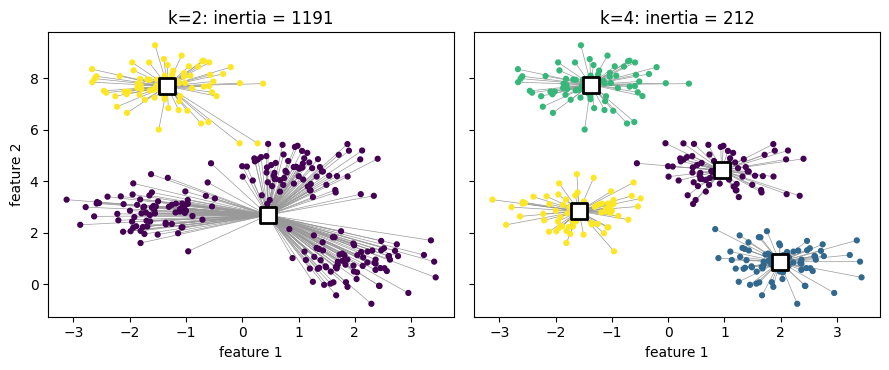

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, k in zip(axes, (2, 4)):
    km_k = KMeans(n_clusters=k, random_state=0, n_init=10).fit(X_blobs)
    own_centroid = km_k.cluster_centers_[km_k.labels_]       # one row per point: the centroid of its cluster
    for point, centre in zip(X_blobs, own_centroid):
        ax.plot([point[0], centre[0]], [point[1], centre[1]], color="0.6", linewidth=0.5)
    ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=km_k.labels_, s=12, cmap="viridis", zorder=3)
    ax.scatter(*km_k.cluster_centers_.T, marker="s", s=120, c="white",
               edgecolors="k", linewidths=2, zorder=4)
    ax.set_title(f"k={k}: inertia = {km_k.inertia_:.0f}")
    ax.set_xlabel("feature 1")
axes[0].set_ylabel("feature 2")
plt.tight_layout()
plt.show()

#### The Palmer Penguins dataset

The **Palmer Penguins** dataset was collected by Kristen Gorman at Palmer Station, Antarctica. It holds 344 records of the physical attributes of penguins in the Palmer Archipelago, belonging to three species; two records have no body measurements at all and are dropped below, leaving 342 (Horst, Hill & Gorman, 2020; *palmerpenguins*, doi:10.5281/zenodo.3960218; data collected by the Palmer Station Antarctica LTER and K. Gorman).

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/palmerpenguins-species.jpg" alt="Illustrations of the three penguin species in the dataset — Chinstrap, Gentoo and Adelie" width="700">

<em>The three species in the dataset. Artwork by Allison Horst (`@allison_horst`), from the
<a href="https://allisonhorst.github.io/palmerpenguins/">palmerpenguins</a> package. Data by
K. Gorman and the Palmer Station Antarctica LTER, released under CC-0.</em>

In [12]:
# Pre-supplied: download the data file and cache it locally.
# You do not need to understand this cell yet — fetching data is covered in the
# reproducible-data-pipelines bonus subchapter.
import pooch

In [13]:
penguins_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/palmer_penguins.csv",
    known_hash="sha256:f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93",
    fname="palmer_penguins.csv",
    path=pooch.os_cache("mlees"),
)

In [14]:
# dropna(subset=...) drops rows with a missing value in the listed columns;
# reset_index(drop=True) renumbers the remaining rows from 0
penguins = pd.read_csv(penguins_path).dropna(
    subset=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
).reset_index(drop=True)

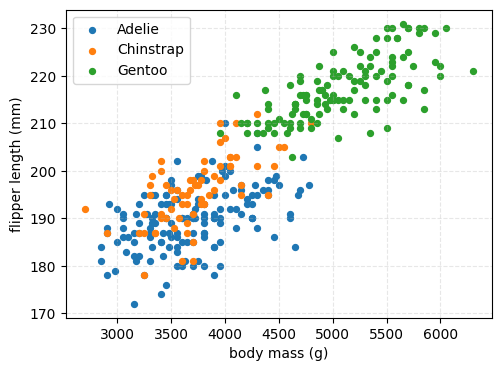

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 4))
for species, group in penguins.groupby("species"):
    ax.scatter(group["body_mass_g"], group["flipper_length_mm"], s=18, label=species)
ax.set_xlabel("body mass (g)")
ax.set_ylabel("flipper length (mm)")
ax.grid(linestyle="--", alpha=0.3)
ax.legend()
plt.show()

On a real dataset the clusters are rarely that obliging. The penguin measurements below have no
species column as far as `KMeans` is concerned — it sees two physical measurements and nothing
else.

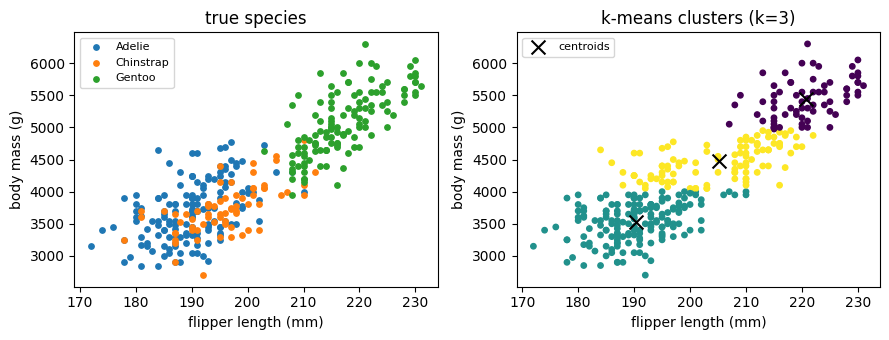

cluster     0    1   2
species               
Adelie      0  116  35
Chinstrap   0   53  15
Gentoo     68    1  54


In [16]:
X_cluster = penguins[["flipper_length_mm", "body_mass_g"]]
kmeans = KMeans(n_clusters=3, random_state=0, n_init=10).fit(X_cluster)
penguins["cluster"] = kmeans.labels_

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for species, group in penguins.groupby("species"):
    axes[0].scatter(group["flipper_length_mm"], group["body_mass_g"], s=15, label=species)
axes[0].set_title("true species")
axes[0].legend(fontsize=8)

axes[1].scatter(X_cluster["flipper_length_mm"], X_cluster["body_mass_g"],
                c=penguins["cluster"], s=15, cmap="viridis")
axes[1].scatter(*kmeans.cluster_centers_.T, marker="x", s=100, color="black", label="centroids")
axes[1].set_title("k-means clusters (k=3)")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("flipper length (mm)")
    ax.set_ylabel("body mass (g)")
plt.tight_layout()
plt.show()

# pd.crosstab counts the rows in each (species, cluster) pair: one row per species, one column per cluster
print(pd.crosstab(penguins["species"], penguins["cluster"]))

The three clusters are three bands of body mass: under 4000 g, 4050 to 4950 g, and above 4975 g. Body mass sets the bands because it is measured in thousands of grams while flipper length varies over only about 60 mm, so it dominates the distance. Gentoo is heavier than the other two species, yet it is split: 68 Gentoo fill the heaviest band, and 54 more land in the middle band with 35 Adelie and 15 Chinstrap. Adelie and Chinstrap overlap in both features and are spread over the same two lower bands. Clustering finds structure in the features you give it; it cannot recover a label those features do not separate.

What if the number of clusters is set to two instead?

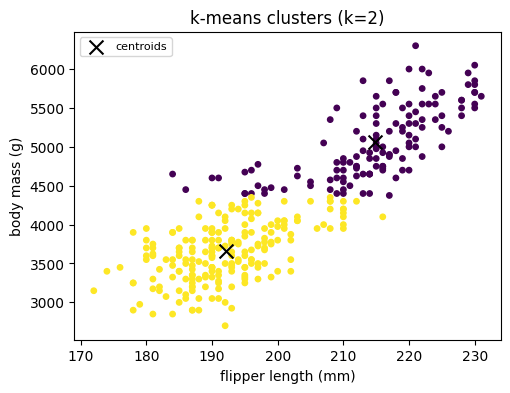

cluster2     0    1
species            
Adelie      14  137
Chinstrap    5   63
Gentoo     114    9


In [17]:
kmeans2 = KMeans(n_clusters=2, random_state=0, n_init=10).fit(X_cluster)
penguins["cluster2"] = kmeans2.labels_

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(X_cluster["flipper_length_mm"], X_cluster["body_mass_g"],
           c=penguins["cluster2"], s=15, cmap="viridis")
ax.scatter(*kmeans2.cluster_centers_.T, marker="x", s=100, color="black", label="centroids")
ax.set_xlabel("flipper length (mm)")
ax.set_ylabel("body mass (g)")
ax.set_title("k-means clusters (k=2)")
ax.legend(fontsize=8)
plt.show()
print(pd.crosstab(penguins["species"], penguins["cluster2"]))

Two clusters look more natural in this plane than three: one holds Gentoo, the other Adelie and Chinstrap together. Which number is right should not be decided by eye.

#### Choosing k: the elbow method

We fixed `k=3` because we already know there are three species — in general the right number of clusters is not known in advance. The elbow method refits `KMeans` across a range of `k` and plots the inertia (the summed squared segment lengths of the figure above, each point's squared distance to its cluster's centroid): inertia always falls as `k` grows, but the rate of improvement drops sharply once extra clusters stop capturing real structure — a bend, or "elbow", in the curve.

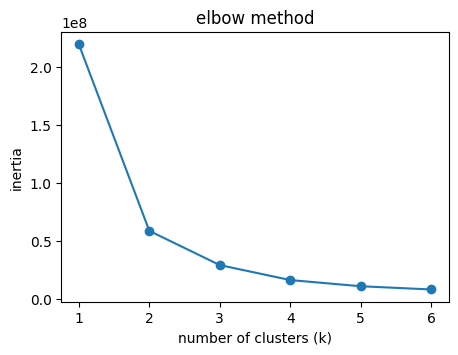

In [18]:
inertias = []
k_values = range(1, 7)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=0, n_init=10).fit(X_cluster)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(list(k_values), inertias, marker="o")
ax.set_xlabel("number of clusters (k)")
ax.set_ylabel("inertia")
ax.set_title("elbow method")
plt.show()

##### Silhouette analysis

The elbow is not always sharp: here the curve bends somewhere between two and four clusters
without saying which. The *silhouette score* puts a number on it. For one observation,

$$S = \frac{b - a}{\max(a, b)},$$

where $a$ is its mean distance to the other points in its own cluster and $b$ its mean distance to
the points of the nearest other cluster. A value near 1 means the observation sits comfortably
inside its own cluster; near 0 means it sits on the boundary between two. Averaged over every
observation, the score can be compared across `k`, and the largest average wins.

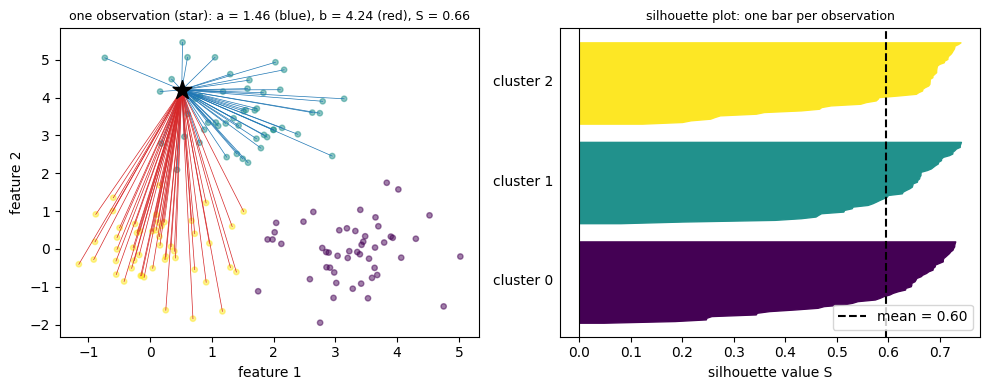

In [19]:
from sklearn.metrics import silhouette_samples

# three overlapping groups of 50 points
X_sil, _ = make_blobs(n_samples=150, centers=[[0, 0], [3, 0], [1.5, 3.5]], cluster_std=0.8, random_state=1)
labels_sil = KMeans(n_clusters=3, random_state=0, n_init=10).fit_predict(X_sil)

# the silhouette of one observation, computed from its distances to all the others
i = 0
dist_to_i = np.sqrt(np.sum((X_sil - X_sil[i]) ** 2, axis=1))
in_own = labels_sil == labels_sil[i]
a = dist_to_i[in_own].sum() / (in_own.sum() - 1)           # mean distance to the rest of its own cluster
others = [c for c in range(3) if c != labels_sil[i]]
b_per_cluster = np.array([dist_to_i[labels_sil == c].mean() for c in others])
nearest = others[np.argmin(b_per_cluster)]                  # the closest other cluster
b = b_per_cluster.min()
s_i = (b - a) / np.max([a, b])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.scatter(X_sil[:, 0], X_sil[:, 1], c=labels_sil, s=15, cmap="viridis", alpha=0.5)
for j in np.where(in_own)[0]:
    ax.plot(*zip(X_sil[i], X_sil[j]), color="tab:blue", linewidth=0.5)
for j in np.where(labels_sil == nearest)[0]:
    ax.plot(*zip(X_sil[i], X_sil[j]), color="tab:red", linewidth=0.5)
ax.scatter(*X_sil[i], marker="*", s=200, color="k", zorder=4)
ax.set_title(f"one observation (star): a = {a:.2f} (blue), b = {b:.2f} (red), S = {s_i:.2f}", fontsize=9)
ax.set_xlabel("feature 1")
ax.set_ylabel("feature 2")

# every observation as one horizontal bar, grouped by cluster and sorted within it
sil_values = silhouette_samples(X_sil, labels_sil)
y_start = 0
for c in range(3):
    values = np.sort(sil_values[labels_sil == c])
    axes[1].fill_betweenx(np.arange(y_start, y_start + len(values)), 0, values, color=plt.cm.viridis(c / 2))
    axes[1].text(-0.05, y_start + len(values) / 2, f"cluster {c}", ha="right", va="center")
    y_start += len(values) + 10
axes[1].axvline(sil_values.mean(), color="k", linestyle="--", label=f"mean = {sil_values.mean():.2f}")
axes[1].axvline(0, color="k", linewidth=0.8)
axes[1].set_xlabel("silhouette value S")
axes[1].set_yticks([])
axes[1].legend(loc="lower right")
axes[1].set_title("silhouette plot: one bar per observation", fontsize=9)
plt.tight_layout()
plt.show()

Left: the star's $a$ is the mean length of the blue segments, to the members of its own cluster, and $b$ the mean length of the red segments, to the nearest other cluster. $S$ is close to 1 when the red segments are much longer than the blue ones. Right: the same calculation for every observation. A cluster whose bars are long and reach past the dashed mean line is compact and well separated; bars that extend to the left of 0 belong to observations that are closer, on average, to another cluster than to their own. The mean of all bars is the score used to compare values of `k`.

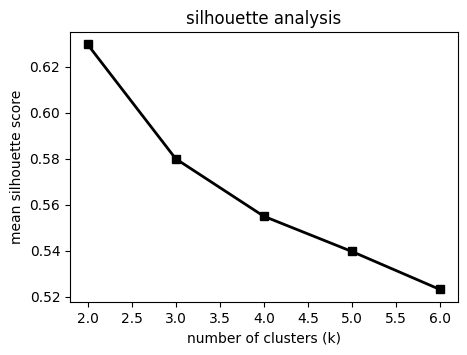

k=2: 0.630
k=3: 0.580
k=4: 0.555
k=5: 0.540
k=6: 0.523


In [20]:
from sklearn.metrics import silhouette_score

silhouettes = []
k_range = range(2, 7)
for k in k_range:
    labels = KMeans(n_clusters=k, random_state=0, n_init=10).fit_predict(X_cluster)
    silhouettes.append(silhouette_score(X_cluster, labels))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(list(k_range), silhouettes, marker="s", color="k", lw=2)
ax.set_xlabel("number of clusters (k)")
ax.set_ylabel("mean silhouette score")
ax.set_title("silhouette analysis")
plt.show()

for k, s in zip(k_range, silhouettes):
    print(f"k={k}: {s:.3f}")

Two clusters score highest, and two clusters is not three species. The elbow could not decide between two and four, and the silhouette score settles on two. Both diagnostics answer the question they were asked, which is how well separated the groups in *these two features* are, not how many species the archipelago holds. A clustering that scores well can still be the wrong grouping for the question you care about.

Gentoo separates because it is
heavier and longer-flippered than the other two; Adelie and Chinstrap overlap because in this
plane they genuinely are alike. Swap body mass for bill length, and the three species separate visually (plot below) — Chinstrap flippers resemble Adelie's, but Chinstrap bills resemble Gentoo's.

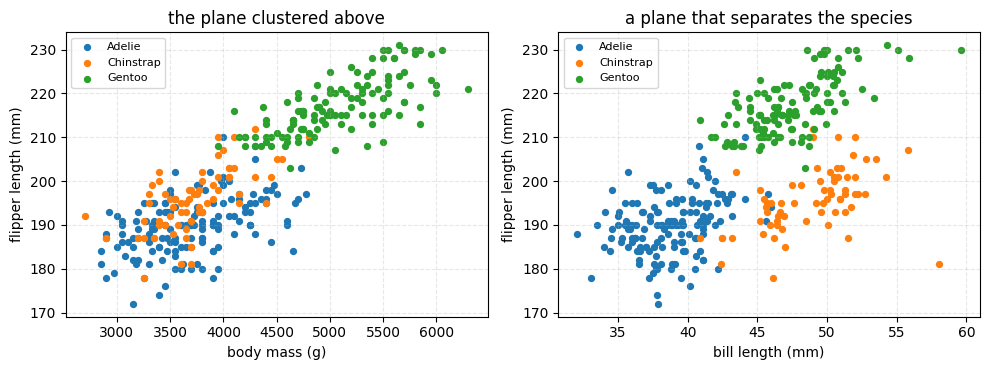

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for species, group in penguins.groupby("species"):
    axes[0].scatter(group["body_mass_g"], group["flipper_length_mm"], s=18, label=species)
    axes[1].scatter(group["bill_length_mm"], group["flipper_length_mm"], s=18, label=species)

axes[0].set_xlabel("body mass (g)")
axes[0].set_title("the plane clustered above")
axes[1].set_xlabel("bill length (mm)")
axes[1].set_title("a plane that separates the species")
for ax in axes:
    ax.set_ylabel("flipper length (mm)")
    ax.grid(linestyle="--", alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Two of the four measurements describe the bill. The raw data calls them *culmen* length and
depth, after the ridge along the top of the bill; the column names here use the plainer word.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/palmerpenguins-bill-dimensions.jpg" alt="A diagram of a penguin head showing which dimension is bill length and which is bill depth" width="600">

<em>What `bill_length_mm` and `bill_depth_mm` measure. Artwork by Allison Horst (`@allison_horst`), from the
<a href="https://allisonhorst.github.io/palmerpenguins/">palmerpenguins</a> package.</em>

#### The silhouette plot depends on the features

A silhouette is measured in the feature space that was clustered, so a different choice of features gives a different answer. The figure below repeats the k=3 silhouette plot for four choices of features. Where a set is *standardised*, each column is shifted to mean 0 and divided by its standard deviation, so that body mass in grams does not outweigh lengths in millimetres.

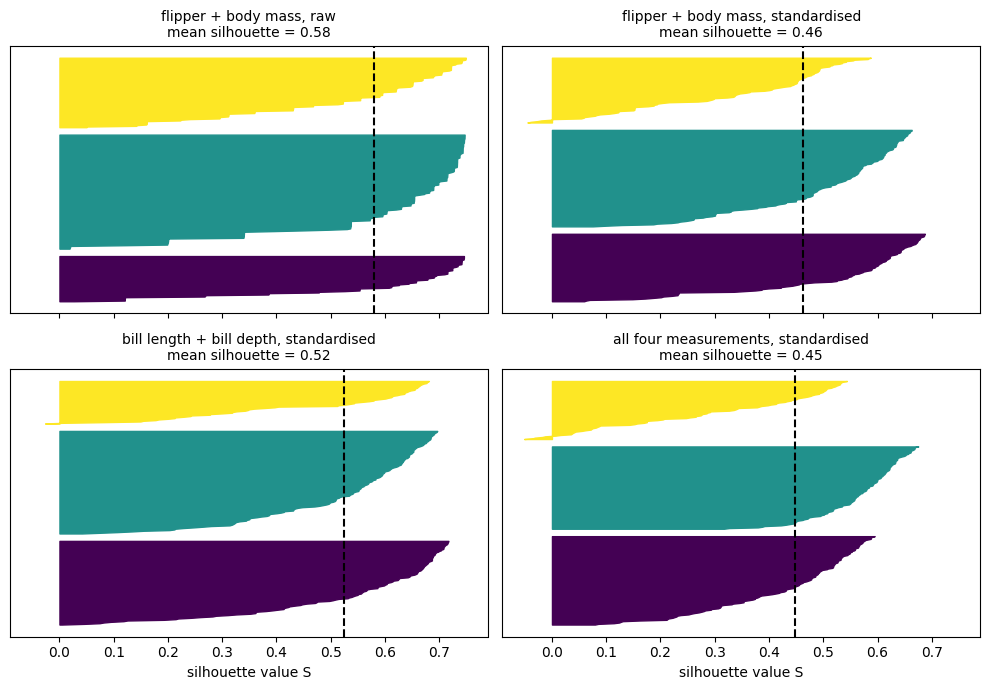

In [22]:
feature_sets = {
    "flipper + body mass, raw": (["flipper_length_mm", "body_mass_g"], False),
    "flipper + body mass, standardised": (["flipper_length_mm", "body_mass_g"], True),
    "bill length + bill depth, standardised": (["bill_length_mm", "bill_depth_mm"], True),
    "all four measurements, standardised": (["bill_length_mm", "bill_depth_mm",
                                             "flipper_length_mm", "body_mass_g"], True),
}

X_sets = {}
for name in feature_sets:
    columns, standardise = feature_sets[name]
    X_set = penguins[columns]
    if standardise:
        X_set = (X_set - X_set.mean()) / X_set.std()
    X_sets[name] = X_set

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
for ax, name in zip(axes.reshape(-1), X_sets):
    labels_set = KMeans(n_clusters=3, random_state=0, n_init=10).fit_predict(X_sets[name])
    sil_set = silhouette_samples(X_sets[name], labels_set)
    y_start = 0
    for c in range(3):
        values = np.sort(sil_set[labels_set == c])
        ax.fill_betweenx(np.arange(y_start, y_start + len(values)), 0, values, color=plt.cm.viridis(c / 2))
        y_start += len(values) + 10
    ax.axvline(sil_set.mean(), color="k", linestyle="--")
    ax.set_title(f"{name}\nmean silhouette = {sil_set.mean():.2f}", fontsize=10)
    ax.set_yticks([])
for ax in axes[1]:
    ax.set_xlabel("silhouette value S")
plt.tight_layout()
plt.show()

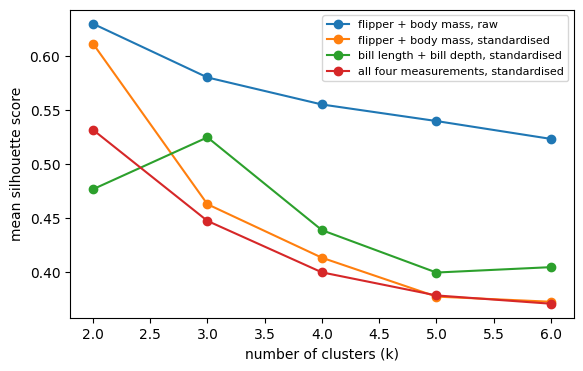

col_0        0    1   2
species                
Adelie       0  147   4
Chinstrap    9    5  54
Gentoo     116    1   6


In [23]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for name in X_sets:
    scores = []
    for k in range(2, 7):
        labels_k = KMeans(n_clusters=k, random_state=0, n_init=10).fit_predict(X_sets[name])
        scores.append(silhouette_score(X_sets[name], labels_k))
    ax.plot(range(2, 7), scores, marker="o", label=name)
ax.set_xlabel("number of clusters (k)")
ax.set_ylabel("mean silhouette score")
ax.legend(fontsize=8)
plt.show()

# how the k=3 clusters from the bill measurements line up with the species
labels_bill = KMeans(n_clusters=3, random_state=0, n_init=10).fit_predict(X_sets["bill length + bill depth, standardised"])
print(pd.crosstab(penguins["species"], labels_bill))

The raw flipper-and-mass set has the highest k=3 score of the four (0.58), although its clusters are the three mass bands that split Gentoo: the score says the bands are well separated in that plane, and says nothing about species. Standardising the same two columns lowers the score to 0.46, and the curve then peaks at k=2. The standardised bill length and depth are the only set whose curve peaks at k=3 (0.52, against 0.48 at k=2), and their three clusters are almost the three species: 147 of 151 Adelie, 54 of 68 Chinstrap and 116 of 123 Gentoo share a cluster. With all four measurements the peak returns to k=2. A silhouette score tests how well the groups are separated in the chosen features; whether those groups are the ones you care about is decided by the choice of features.

#### Dimensionality reduction with PCA

`PCA` finds new axes — linear combinations of the original features — ordered by how much variance they capture, so a handful of components can summarise many correlated measurements. Scale first, with `StandardScaler`, which subtracts each feature's mean and divides by its standard deviation: PCA follows variance, so without scaling, body mass, in thousands of grams, would dominate bill depth, in tens of millimetres.

Two features show the idea. Flipper length and body mass are correlated (0.87), so after standardising, the cloud of penguins is an ellipse tilted along the diagonal. The first principal component (PC1) is the direction of the ellipse's long axis, the direction along which the points vary most. PC2 is perpendicular to it and holds what variance remains. Dropping PC2 means projecting every point onto the PC1 axis (red dotted segments) and keeping one number per penguin instead of two.

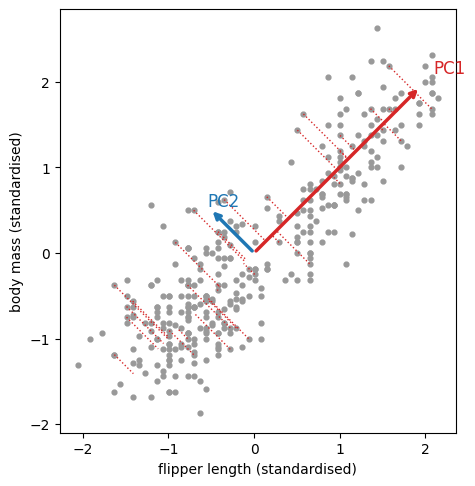

components (one row each):
 [[ 0.71  0.71]
 [-0.71  0.71]]
share of the variance: [0.94 0.06]


In [24]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pair_scaled = StandardScaler().fit_transform(penguins[["flipper_length_mm", "body_mass_g"]])
pca_pair = PCA(n_components=2).fit(pair_scaled)
pc1 = pca_pair.components_[0]                                # unit vector along PC1

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(pair_scaled[:, 0], pair_scaled[:, 1], s=12, color="0.6")
for point in pair_scaled[::10]:                              # every tenth penguin
    foot = (point @ pc1) * pc1                               # its projection onto the PC1 axis
    ax.plot([point[0], foot[0]], [point[1], foot[1]], color="tab:red", linestyle=":", linewidth=1)
for k, color in enumerate(["tab:red", "tab:blue"]):
    # arrow length = 2 standard deviations of the data along that component
    arrow = 2 * np.sqrt(pca_pair.explained_variance_[k]) * pca_pair.components_[k]
    ax.annotate("", xy=arrow, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=color, linewidth=2.5))
    ax.text(arrow[0] * 1.08, arrow[1] * 1.08, f"PC{k + 1}", color=color, fontsize=12)
ax.set_aspect("equal")
ax.set_xlabel("flipper length (standardised)")
ax.set_ylabel("body mass (standardised)")
plt.show()

print("components (one row each):\n", pca_pair.components_.round(2))
print("share of the variance:", pca_pair.explained_variance_ratio_.round(2))

Each row of `components_` lists the weights of the original features in one component. PC1 weights the two standardised features equally, (0.71, 0.71) up to an overall sign, which is the diagonal; PC2 is perpendicular to it. PC1 holds 94 % of the total variance, so one number per penguin keeps almost everything the two measurements say. With four features the same construction happens in four dimensions, which cannot be drawn. The scatter below shows the penguins in the plane of the first two components.

explained variance ratio: [0.688 0.193]


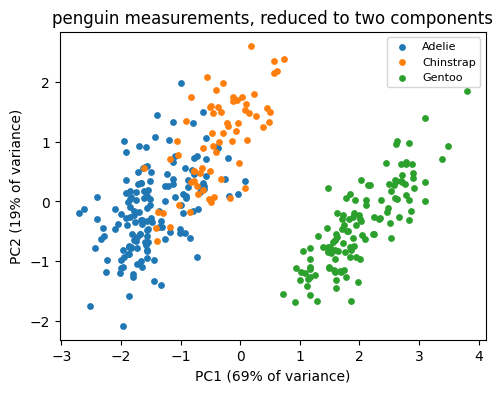

In [25]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X_scaled = StandardScaler().fit_transform(penguins[features])
pca = PCA(n_components=2).fit(X_scaled)
pc_scores = pca.transform(X_scaled)
penguins["pc1"], penguins["pc2"] = pc_scores[:, 0], pc_scores[:, 1]
print("explained variance ratio:", pca.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(figsize=(5.5, 4))
for species, group in penguins.groupby("species"):
    ax.scatter(group["pc1"], group["pc2"], s=15, label=species)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("penguin measurements, reduced to two components")
ax.legend(fontsize=8)
plt.show()

PCA needs no target either, and unlike k-means it needs no assumed number of groups. Two components keep 88 % of the variance of the four measurements, using all four at once instead of picking two by hand. Gentoo separates from the other two in this plane; Adelie and Chinstrap still overlap.

<details>
<summary><b>🔍 Going deeper: what is inside a principal component</b></summary>

A principal component is a direction in feature space: one row of `pca.components_`, with one weight per original feature and length 1. The rows are perpendicular to each other, so together they are a new set of axes, a *basis*, obtained by rotating the original ones. A penguin's score on a component is its coordinate along that axis, `centred_data @ components_.T`. Keeping all four components loses nothing, since the rotation can be undone. Keeping two gives an approximation, and the squared error is exactly the variance of the discarded components.

```python
X_centred = X_scaled - X_scaled.mean(axis=0)
print(pca.components_.round(2))                         # rows: PC1, PC2; columns: the four features
print((pca.components_ @ pca.components_.T).round(2))   # identity matrix: unit length, mutually perpendicular

scores_by_hand = X_centred @ pca.components_.T
print(np.allclose(scores_by_hand, pc_scores))           # True: the scores are projections

X_back = pc_scores @ pca.components_                    # reconstruction from two components
lost = np.sum((X_centred - X_back) ** 2) / np.sum(X_centred ** 2)
print(round(lost, 3), round(1 - pca.explained_variance_ratio_.sum(), 3))   # the same number

# the components are the eigenvectors of the covariance matrix, the variances its eigenvalues
eigenvalues, eigenvectors = np.linalg.eigh(np.cov(X_centred.T))
print(eigenvalues[::-1][:2].round(3), pca.explained_variance_.round(3))    # eigh sorts ascending
```

Reading the weights: PC1 puts positive weight on bill length, flipper length and body mass and negative weight on bill depth, and PC2 is almost entirely the two bill measurements. A label such as "overall size" for PC1 is an interpretation of those weights, and the sign of a whole component is arbitrary: `-pc1` describes the same axis.

Climate science knows the same calculation as *empirical orthogonal function* (EOF) analysis. The samples are time steps and the features are grid points, so the data matrix has shape (n_times, n_gridpoints), holding anomalies. Each row of `components_`, reshaped back onto the map, is an EOF: a spatial pattern. Its scores are the principal-component time series, which say how strongly that pattern is present at each time. Two practical differences: the anomalies are usually weighted by $\sqrt{\cos(\text{latitude})}$, so that area rather than the number of grid points sets the variance, and with many more grid points than times there are at most n_times − 1 components with nonzero variance.

Two cautions. PCA orders directions by variance, not by physical importance: the leading component of an unprocessed field is often the seasonal cycle, and a small-variance component can be the one that matters. And because the components are forced to be perpendicular, two physical modes with similar variance get mixed into a pair of components that each describe neither.

</details>

### Linear Classification

Not every target is continuous. When `y` is a category, a classifier follows the identical `fit`/`predict` interface. `LogisticRegression` is the classification analogue of linear regression: it fits a linear boundary in feature space and reports, for each observation, the probability that it belongs to each class.

The bill plane separated the species where body mass could not. Here, the task is to tell an Adelie from a Chinstrap using nothing but the two bill measurements. Gentoo is left out — it is the easy case, separable on almost any pair of features — leaving the two species that overlap.

Look at the two measurements one at a time first. Bill length separates the two species almost completely; bill depth barely separates them at all.

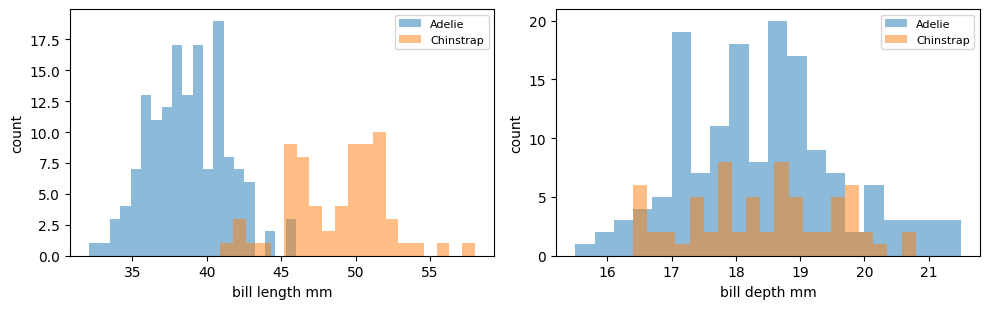

In [26]:
# .isin(list) is True for the rows whose value appears in the list
two_species = penguins[penguins["species"].isin(["Adelie", "Chinstrap"])]
bill_columns = ["bill_length_mm", "bill_depth_mm"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, column in zip(axes, bill_columns):
    for species, group in two_species.groupby("species"):
        ax.hist(group[column], bins=20, alpha=0.5, label=species)
    ax.set_xlabel(f"{column.replace('_', ' ')}")
    ax.set_ylabel("count")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

A classifier must also be judged on observations it was not trained on, so the data are split first.

In [27]:
from sklearn.linear_model import LogisticRegression

X_bill = two_species[bill_columns]
y_species = two_species["species"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_bill, y_species, test_size=0.3, random_state=0, stratify=y_species
)
print(Xb_train.describe().round(2))

       bill_length_mm  bill_depth_mm
count          153.00         153.00
mean            42.07          18.46
std              5.49           1.20
min             33.10          15.90
25%             37.80          17.60
50%             40.80          18.50
75%             46.10          19.20
max             58.00          21.50


#### Standardisation

Bill length runs from about 33 to 58 mm and bill depth from about 16 to 22 mm, so the spreads of the two features differ by a factor of about four. Left alone, the fitted weights would reflect that difference as much as the information in the features. *Standardisation* removes it: subtract each feature's mean and divide by its standard deviation,

$$x_{\text{standard}} = \frac{x - \operatorname{mean}(x)}{\operatorname{std}(x)},$$

so that every feature has mean 0 and standard deviation 1, in units of its own spread.

In [28]:
# ddof=0 divides by n, the convention StandardScaler uses
length_standard = (Xb_train["bill_length_mm"] - Xb_train["bill_length_mm"].mean()) / Xb_train["bill_length_mm"].std(ddof=0)
depth_standard = (Xb_train["bill_depth_mm"] - Xb_train["bill_depth_mm"].mean()) / Xb_train["bill_depth_mm"].std(ddof=0)
print("bill length:", round(length_standard.min(), 2), "to", round(length_standard.max(), 2))
print("bill depth: ", round(depth_standard.min(), 2), "to", round(depth_standard.max(), 2))

bill length: -1.64 to 2.91
bill depth:  -2.14 to 2.54


`StandardScaler` does the same thing as an estimator: `fit` learns each column's mean and standard deviation, and `transform` applies them. The scaler is fitted on the training set only, and the same transformation is then applied to the test set. A scaler fitted on all the data would prepare the training set with the test observations' means and spreads, so the test score would no longer come from data the model has never seen (*data leakage*). Many estimators (regularised regressions, distance-based methods, and `LogisticRegression`, which is regularised by default) need features on comparable scales.

In [29]:
scaler = StandardScaler().fit(Xb_train)           # mean and std of the training set only
Xb_train_scaled = scaler.transform(Xb_train)
Xb_test_scaled = scaler.transform(Xb_test)        # the same mean and std, applied to the test set

bill_clf = LogisticRegression().fit(Xb_train_scaled, yb_train)
print("test accuracy:", round(bill_clf.score(Xb_test_scaled, yb_test), 3))

test accuracy: 0.97


For a regression the steps are the same, and `.score` returns $R^2$ instead of accuracy. For ordinary least squares, scaling the inputs changes the units of the weights but not the predictions, so the two scores below agree:

In [30]:
scaler_lapse = StandardScaler().fit(X_train)
lin_scaled = LinearRegression().fit(scaler_lapse.transform(X_train), y_train)
print("scaled inputs, test R^2:", round(lin_scaled.score(scaler_lapse.transform(X_test), y_test), 3))
print("raw inputs, test R^2:   ", round(model.score(X_test, y_test), 3))
# scaling matters for regularised and distance-based models, where unscaled features distort the fit

scaled inputs, test R^2: 0.947
raw inputs, test R^2:    0.947


The fitted model is a straight line through the standardised bill plane: one weight per feature
plus an intercept. Reading the weights says which measurement the decision actually rests on.

bill_length_mm    3.79
bill_depth_mm    -1.19
dtype: float64
intercept: -1.79


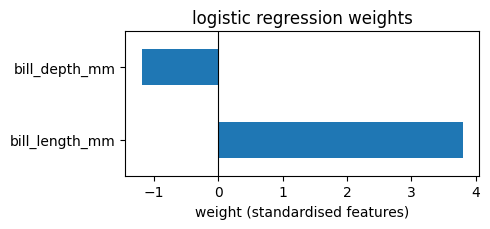

In [31]:
weights = pd.Series(bill_clf.coef_[0], index=bill_columns)
intercept = bill_clf.intercept_[0]
print(weights.round(2))
print("intercept:", round(intercept, 2))

fig, ax = plt.subplots(figsize=(5, 2.4))
weights.plot.barh(ax=ax, color="tab:blue")
ax.axvline(0, color="k", linewidth=0.8)
ax.set_xlabel("weight (standardised features)")
ax.set_title("logistic regression weights")
plt.tight_layout()
plt.show()

# the boundary is the line where the weighted sum crosses zero:
#     w1 * bill_length + w2 * bill_depth + intercept = 0
# bill length carries the larger weight, matching the histograms above

Predicting the class of every point on a fine grid draws that line directly: the decision boundary, with the test penguins on top.

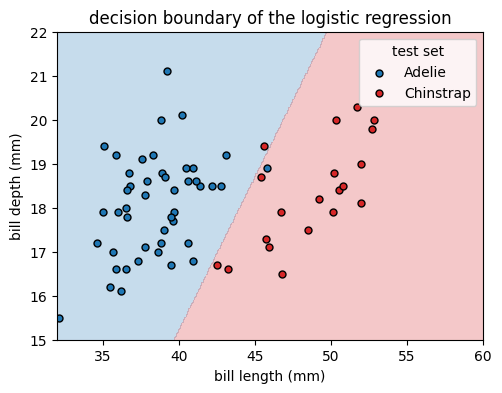

In [32]:
length_grid, depth_grid = np.meshgrid(np.linspace(32, 60, 300), np.linspace(15, 22, 300))
grid_points = pd.DataFrame({"bill_length_mm": length_grid.reshape(-1),
                            "bill_depth_mm": depth_grid.reshape(-1)})
is_chinstrap = (bill_clf.predict(scaler.transform(grid_points)) == "Chinstrap").reshape(length_grid.shape)

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.contourf(length_grid, depth_grid, is_chinstrap.astype(int), levels=[-0.5, 0.5, 1.5],
            colors=["tab:blue", "tab:red"], alpha=0.25)
for species, color in [("Adelie", "tab:blue"), ("Chinstrap", "tab:red")]:
    test_birds = Xb_test[yb_test == species]
    ax.scatter(test_birds["bill_length_mm"], test_birds["bill_depth_mm"],
               color=color, edgecolors="k", s=25, label=species)
ax.set_xlabel("bill length (mm)")
ax.set_ylabel("bill depth (mm)")
ax.set_title("decision boundary of the logistic regression")
ax.legend(title="test set")
plt.show()

The few test birds on the wrong side of the line are the misclassifications behind the test accuracy above.

## 1.8.2 Statistical Graphics with seaborn

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/seaborn_logo.svg" alt="The seaborn project logo" width="500">

<em>The seaborn logo, from the project's own <a href="https://seaborn.pydata.org/">documentation</a>.</em>

### seaborn versus matplotlib

seaborn is not a replacement for matplotlib but a layer on top of it: pass column names instead of extracted arrays, and get a sensible default style, a legend, and statistical summaries such as densities and fitted trend lines, all in one call. `ax=` still accepts a matplotlib axes, so the two compose rather than compete; reach for matplotlib directly whenever a plot needs more control than seaborn's defaults give you.

Here is a set of random walks drawn with matplotlib's classic style:

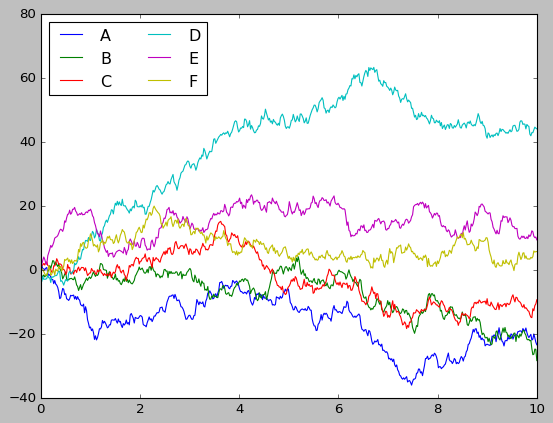

In [33]:
x = np.linspace(0, 10, 500)
walks = np.cumsum(rng.normal(size=(500, 6)), axis=0)

with plt.style.context("classic"):
    plt.plot(x, walks)
    plt.legend(list("ABCDEF"), ncol=2, loc="upper left")
    plt.show()

`sns.set_theme()` replaces matplotlib's default style for every figure that follows, so the same plotting code gives a different figure:

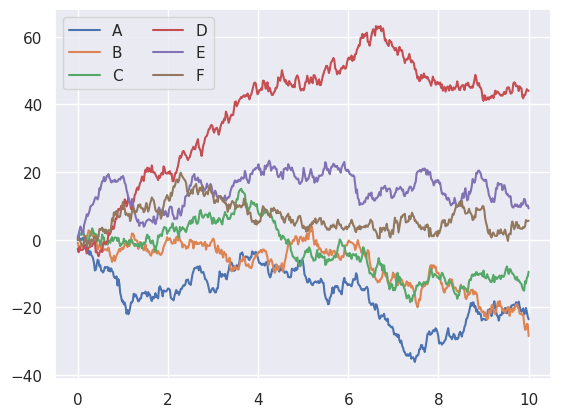

In [34]:
import seaborn as sns

sns.set_theme()
plt.plot(x, walks)
plt.legend(list("ABCDEF"), ncol=2, loc="upper left")
plt.show()

### Exploring Datasets with seaborn

seaborn provides high-level commands for the plot types used in statistical data exploration, and some statistical model fitting. Everything below could be done with raw matplotlib commands — which is what seaborn calls underneath — but seaborn's interface is much more convenient.

#### Histograms, KDE, and densities

Often in statistical visualisation, all you want is the distribution of a variable, split by group. With matplotlib that takes a loop over the groups:

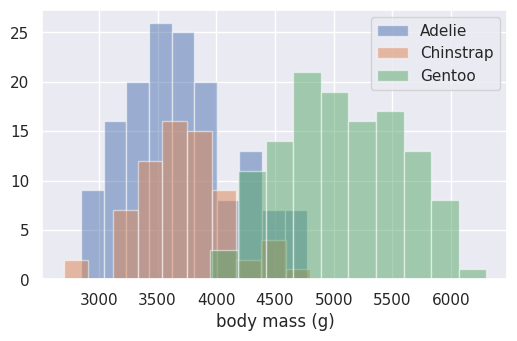

In [35]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for species, group in penguins.groupby("species"):
    ax.hist(group["body_mass_g"], alpha=0.5, label=species)
ax.set_xlabel("body mass (g)")
ax.legend()
plt.show()

`sns.kdeplot` estimates a smooth density for each group instead, and `hue=` splits the data by a categorical column in the same call — no loop needed:

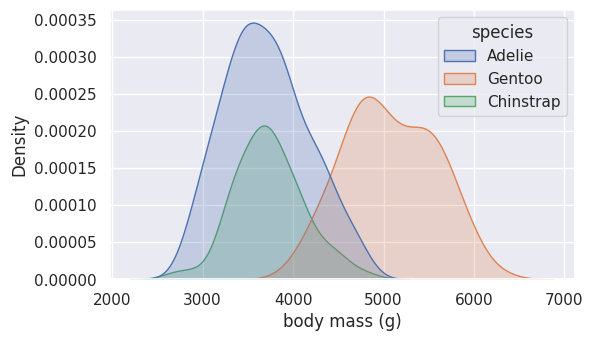

In [36]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.kdeplot(data=penguins, x="body_mass_g", hue="species", fill=True, ax=ax)
ax.set_xlabel("body mass (g)")
plt.show()

The look of a seaborn plot can be changed in the same call, with keyword arguments for the line style and width, and with matplotlib on the axes it returns:

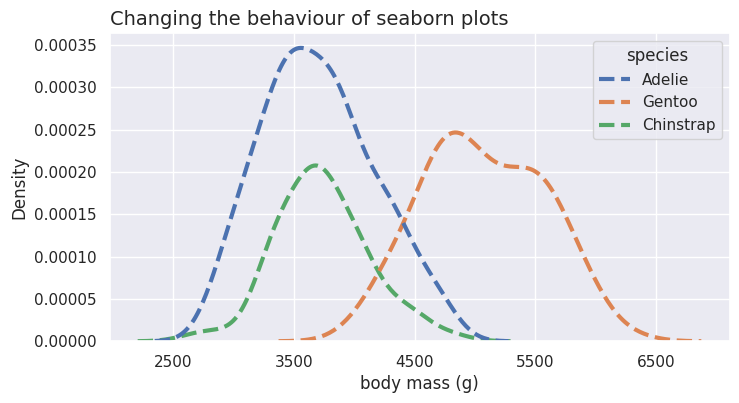

In [37]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(data=penguins, x="body_mass_g", hue="species", fill=False, ax=ax,
            linestyle="--", linewidth=3)
ax.set_xticks([2500, 3500, 4500, 5500, 6500])
ax.set_xlabel("body mass (g)")
ax.set_title("Changing the behaviour of seaborn plots", loc="left", fontsize=14)
plt.show()

#### KDE

A kernel density estimate (KDE) is analogous to a histogram, but instead of counting observations into bins it places a small smooth bump on each one and adds them up, which gives a continuous estimate of the probability density function. Relative to a histogram, a KDE is less cluttered and easier to read, especially when several distributions are drawn together. It has two weaknesses, both visible below:

- a **bounded** variable, such as precipitation or burned area, which cannot be negative, gets density on the impossible side of its bound, because the bumps spread past it; `cut=0` stops the curve at the most extreme data points;
- the result depends on the **smoothing** (the bandwidth) as much as a histogram depends on its bins; `bw_adjust` scales it, and too much smoothing hides structure while too little invents it.

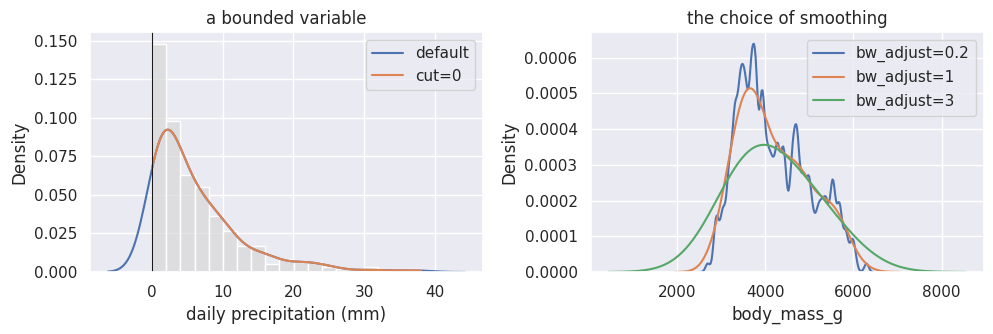

In [38]:
precip_mm = pd.Series(rng.exponential(6.0, 300), name="daily precipitation (mm)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(precip_mm, stat="density", color="0.85", ax=ax[0])
sns.kdeplot(precip_mm, ax=ax[0], label="default")
sns.kdeplot(precip_mm, ax=ax[0], cut=0, label="cut=0")
ax[0].axvline(0, color="k", linewidth=0.8)
ax[0].set_title("a bounded variable")
ax[0].legend()
for bw in [0.2, 1, 3]:
    sns.kdeplot(data=penguins, x="body_mass_g", bw_adjust=bw, ax=ax[1], label=f"bw_adjust={bw}")
ax[1].set_title("the choice of smoothing")
ax[1].legend()
plt.tight_layout()
plt.show()

`sns.histplot` draws the histogram itself, with the same `data=`/`x=`/`hue=` arguments. `stat="density"` scales the bars so that their area is 1, which puts them on the same axis as a KDE, and `kde=True` overlays one:

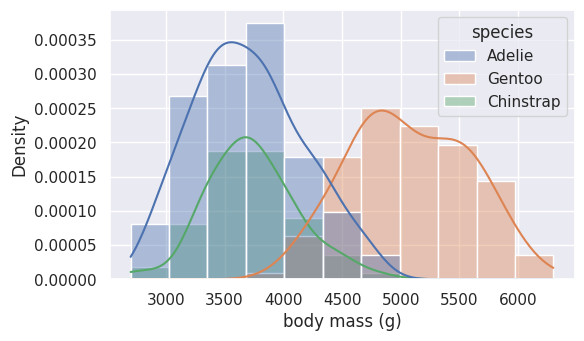

In [39]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(data=penguins, x="body_mass_g", hue="species", stat="density", kde=True, alpha=0.4, ax=ax)
ax.set_xlabel("body mass (g)")
plt.show()

`sns.displot` builds the whole figure in one line: `kind=` chooses a histogram or a KDE, `kde=True` overlays the density, and `rug=True` marks every observation along the axis.

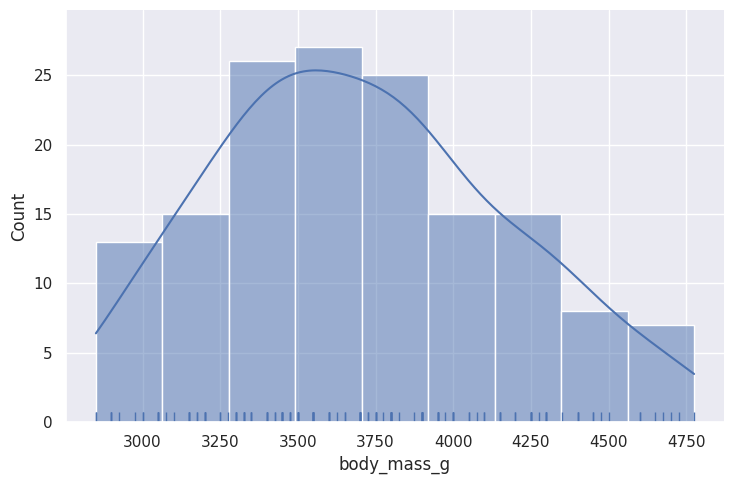

In [40]:
adelie = penguins[penguins["species"] == "Adelie"]
sns.displot(data=adelie, x="body_mass_g", kind="hist", kde=True, rug=True, aspect=1.5)
plt.show()

With `hue=`, the densities are by default normalised *together*, so each group's area is proportional to its share of the data: Chinstrap, with 68 birds against Adelie's 151, gets a smaller curve. `common_norm=False` normalises each group on its own, which compares the *shapes* of the distributions rather than their sizes. Neither is wrong; they answer different questions.

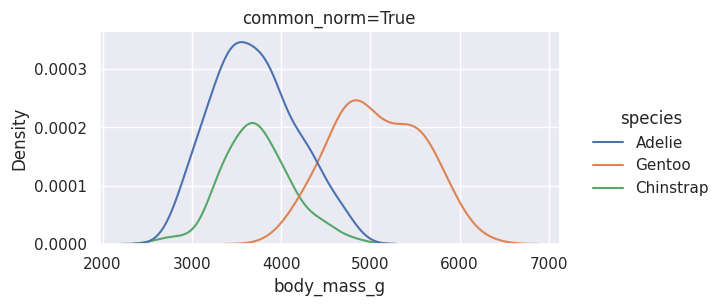

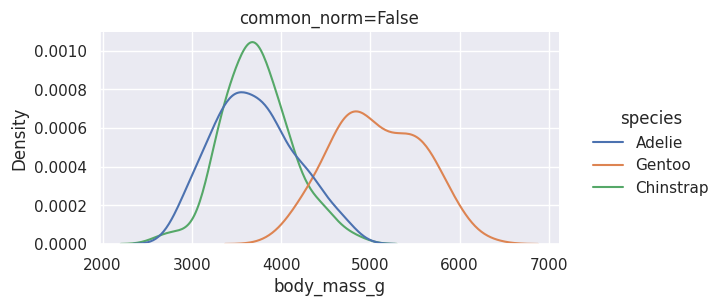

In [41]:
for common in [True, False]:
    sns.displot(data=penguins, x="body_mass_g", hue="species", kind="kde",
                common_norm=common, height=3, aspect=2)
    plt.title(f"common_norm={common}")
    plt.show()

#### Two variables at once

`kdeplot` also works on two variables at once, showing where two measurements co-vary rather than just their individual spreads:

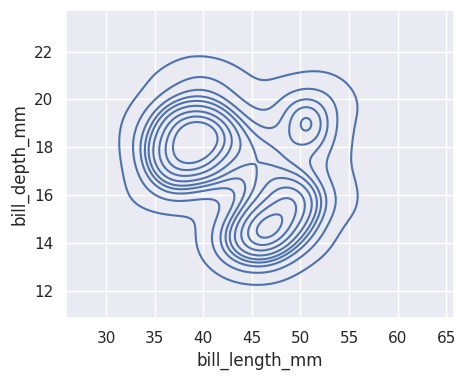

In [42]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.kdeplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", ax=ax)
plt.show()

`jointplot` adds the two 1D marginal densities around the 2D view. `kind="kde"` draws densities; `kind="hex"` draws a two-dimensional histogram of hexagonal bins, which suits large datasets better than a scatter. `sns.axes_style` is a context manager: inside the `with` block the figure gets a different style (here a plain white background), and the global style comes back afterwards. Its other settings are in the [jointplot documentation](https://seaborn.pydata.org/generated/seaborn.jointplot.html).

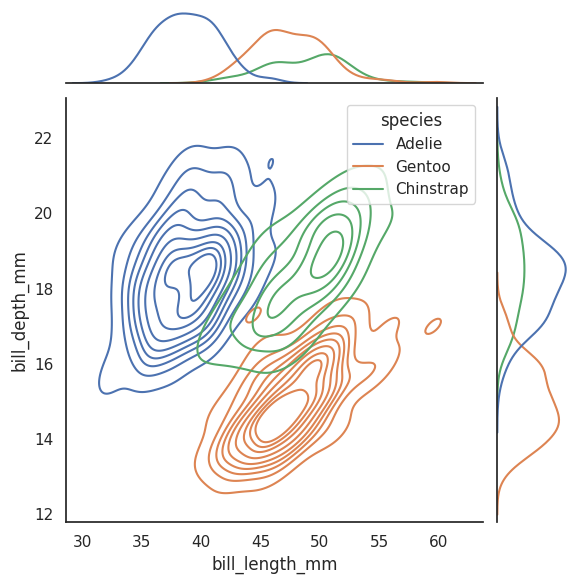

In [43]:
with sns.axes_style("white"):
    sns.jointplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", hue="species", kind="kde")

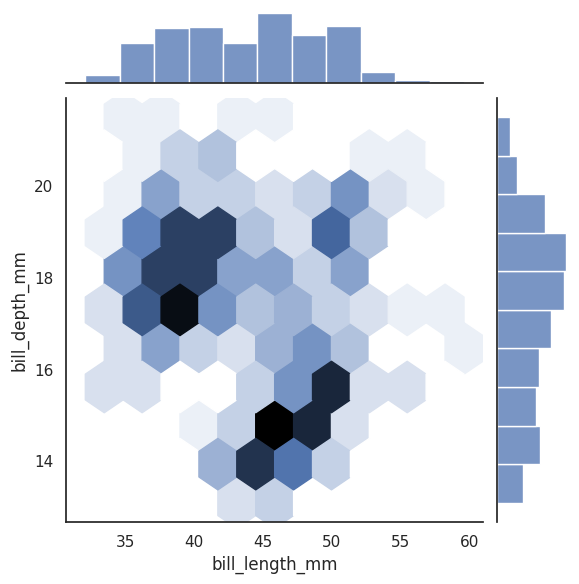

In [44]:
with sns.axes_style("white"):
    sns.jointplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", kind="hex")
plt.show()

seaborn also includes statistical modelling utilities, such as `regplot`, which fits and draws a linear regression with its confidence band — the lapse-rate fit from the start of this subchapter, in one call:

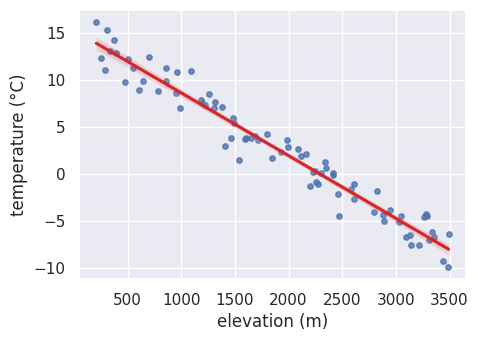

In [45]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.regplot(data=df, x="elevation_m", y="temp_celsius", ax=ax,
            scatter_kws={"s": 15}, line_kws={"color": "tab:red"})
ax.set_xlabel("elevation (m)")
ax.set_ylabel("temperature (°C)")
plt.show()

### Faceted Histograms

Sometimes the best view of a dataset is a grid of histograms of its subsets. [`FacetGrid`](https://seaborn.pydata.org/generated/seaborn.FacetGrid.html) makes one: `row=` and `col=` name the categorical columns that split the data, and `.map` draws the same plot in every panel.

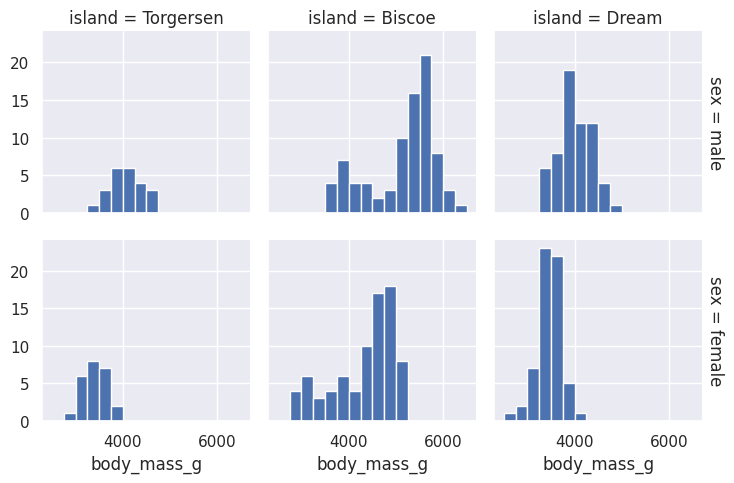

In [46]:
grid = sns.FacetGrid(penguins, row="sex", col="island", margin_titles=True, height=2.5)
grid.map(plt.hist, "body_mass_g", bins=np.linspace(2500, 6500, 17))
plt.show()

`sns.displot` builds the same kind of grid in one call, with `col=` (and `row=`) on a figure-level plot:

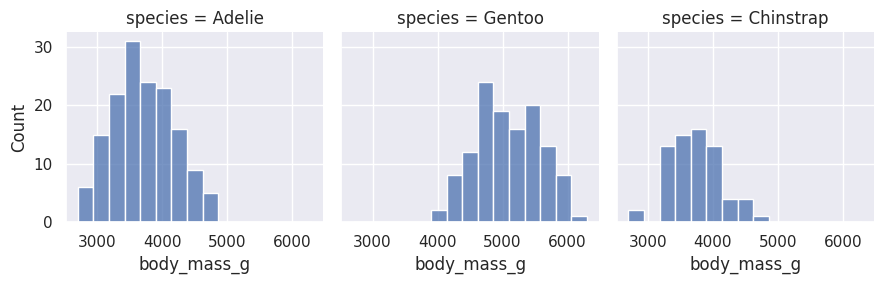

In [47]:
sns.displot(data=penguins, x="body_mass_g", col="species", bins=15, height=3)
plt.show()

### Categorical Plots

[`catplot`](https://seaborn.pydata.org/generated/seaborn.catplot.html) relates a numerical variable to one or more categorical ones: it shows how a quantity is distributed within each category, even though one axis is a number and the other a label. `kind=` chooses the representation.

#### Box plots

A box plot summarises a distribution's median, quartiles, and outliers per category — more compact than a histogram when comparing several groups at once.

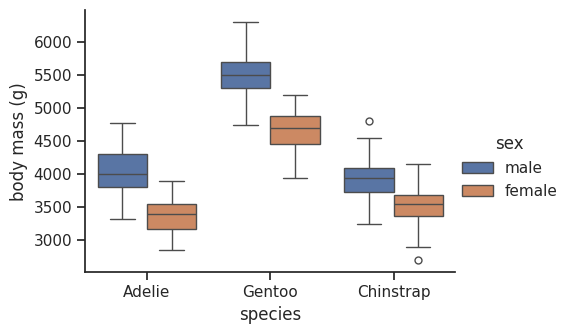

In [48]:
with sns.axes_style(style="ticks"):
    g = sns.catplot(data=penguins, x="species", y="body_mass_g", hue="sex", kind="box", height=3.5, aspect=1.4)
    g.set_axis_labels("species", "body mass (g)")
plt.show()

The axes-level `sns.boxplot` draws the same thing into an axes you created:

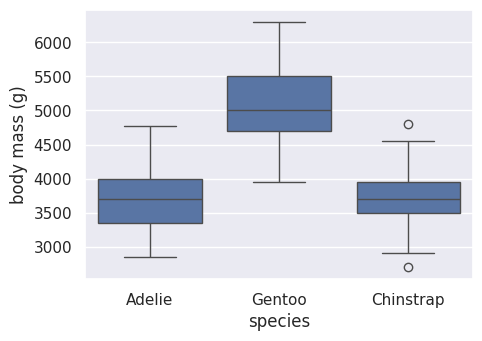

In [49]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.boxplot(data=penguins, x="species", y="body_mass_g", ax=ax)
ax.set_ylabel("body mass (g)")
plt.show()

#### Bar plots

`kind="count"` counts the observations in each category, with no numeric variable at all. Here, the number of penguins measured in each year:

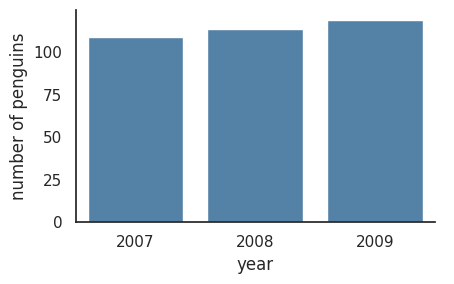

In [50]:
with sns.axes_style("white"):
    g = sns.catplot(data=penguins, x="year", kind="count", color="steelblue", aspect=1.5, height=3)
    g.set_ylabels("number of penguins")
plt.show()

`hue=` splits each bar by a second category, here by island:

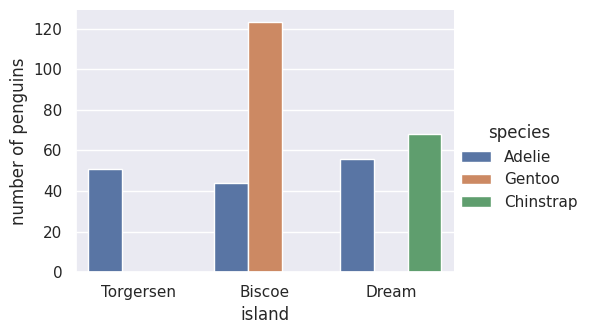

In [51]:
g = sns.catplot(data=penguins, x="island", hue="species", kind="count", height=3.5, aspect=1.4)
g.set_ylabels("number of penguins")
plt.show()

`sns.barplot` instead aggregates a numeric column per category (the mean, by default) and draws the result with an error bar — a quick alternative to a manual `groupby` and hand-drawn bar chart:

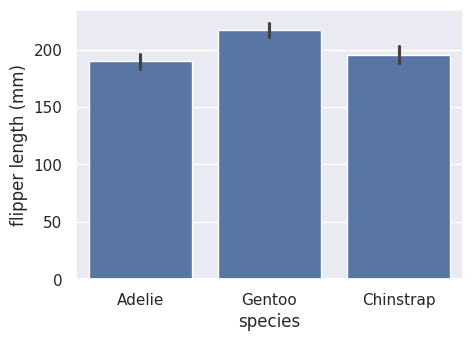

In [52]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(data=penguins, x="species", y="flipper_length_mm", ax=ax, errorbar="sd")
ax.set_ylabel("flipper length (mm)")
plt.show()

### Heat Maps

A heat map shows a matrix as a grid of coloured cells, so a numerical variable can be read as a function of two others, continuous or categorical. `pd.crosstab` counts how often each combination of two categories occurs, and the [heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html) of that table shows which species lives on which island:

island     Biscoe  Dream  Torgersen
species                            
Adelie         44     56         51
Chinstrap       0     68          0
Gentoo        123      0          0


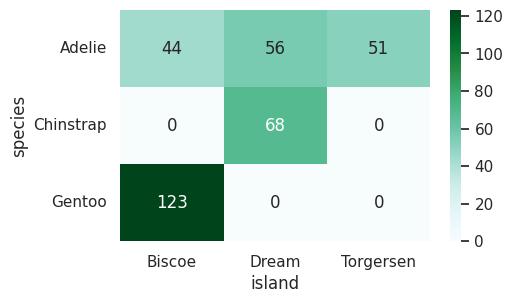

In [53]:
species_by_island = pd.crosstab(penguins["species"], penguins["island"])
print(species_by_island)

fig, ax = plt.subplots(figsize=(5, 3))
sns.heatmap(species_by_island, annot=True, fmt="d", cmap="BuGn", ax=ax)
ax.tick_params(axis="y", rotation=0)   # keep the species labels horizontal
plt.show()

Gentoo were measured only on Biscoe and Chinstrap only on Dream, while Adelie appear on all three islands.

A correlation analysis fits in a few characters the same way: `corr` gives the pairwise Pearson correlation of every pair of numeric columns, and the heat map shows the whole matrix at once.

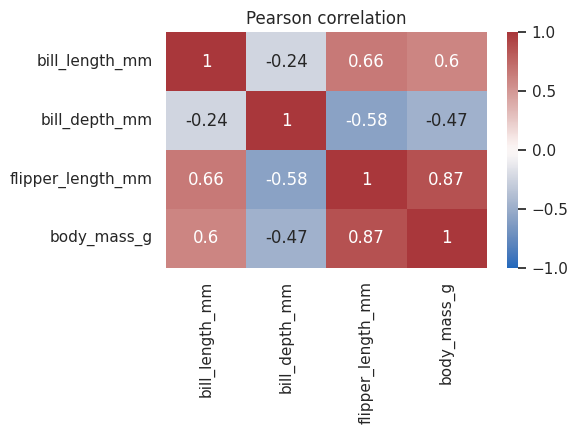

In [54]:
measurements = penguins[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(measurements.corr().round(2), annot=True, cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation")
plt.tight_layout()
plt.show()

What do you notice? Body mass and flipper length rise together (0.87), while bill depth is negatively correlated with every other measurement. For bill length and bill depth the sign is the surprise: pooled over all 342 birds the correlation is −0.24, yet within each species it is positive (0.39 for Adelie, 0.65 for Chinstrap, 0.64 for Gentoo). The pooled value mixes three groups that differ in both measurements — Gentoo have long, shallow bills and Adelie short, deep ones — so a correlation computed on pooled data can have the opposite sign to the one inside each group.

## *When generated code lies: scoring on the training data*

Asked to "evaluate the model", an assistant fits a flexible model and reports $R^2$ on the same data it trained on. On a small, noisy sample a high-degree polynomial fits almost perfectly — and predicts new points disastrously.

`PolynomialFeatures(degree=8)` adds the columns x², x³, …, x⁸ to the feature matrix, so the linear model can bend into an eighth-degree curve. `fit_transform` builds those columns for the training set, and `transform` builds them for the test set.

In [55]:
from sklearn.preprocessing import PolynomialFeatures

rng2 = np.random.default_rng(1)
elevation_km = np.linspace(0.2, 3.5, 20)
temp_small_celsius = 15.0 - 6.5 * elevation_km + rng2.normal(0, 2.0, 20)   # noisy lapse rate, km
X_small = elevation_km.reshape(-1, 1)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(X_small, temp_small_celsius, test_size=0.4, random_state=0)

poly = PolynomialFeatures(degree=8)
Xs_tr_poly = poly.fit_transform(Xs_tr)          # columns 1, x, x^2, ..., x^8
Xs_te_poly = poly.transform(Xs_te)

overfit = LinearRegression().fit(Xs_tr_poly, ys_tr)
print("degree-8 R^2 on TRAINING data:", round(r2_score(ys_tr, overfit.predict(Xs_tr_poly)), 3))

degree-8 R^2 on TRAINING data: 0.984


In [56]:
linear = LinearRegression().fit(Xs_tr, ys_tr)
print("degree-8 R^2 on TEST data:", round(r2_score(ys_te, overfit.predict(Xs_te_poly)), 1))
print("linear    R^2 on TEST data:", round(r2_score(ys_te, linear.predict(Xs_te)), 3))

degree-8 R^2 on TEST data: -846.5
linear    R^2 on TEST data: 0.984


**⚠️ Diagnosis: a training score is not performance**

The training $R^2$ near 1.0 only shows that the degree-8 polynomial curve passes close to its own training points (its held-out $R^2$ above is negative) — with eight free coefficients it bent to match the noise in that particular sample rather than the underlying trend. Evaluated on held-out data the same model is catastrophic, while the simple linear model — the correct physical form — generalises well. Only the test score reflects how the model performs on data it has not seen.

**ℹ️ Quick exercise: recover the lapse rate honestly**

Split the `df` data into train and test, fit a `LinearRegression` of `temp_celsius` on `elevation_m`, and report the recovered lapse rate (°C km⁻¹) and the test $R^2$.


<details>
<summary><b>✅ Solution</b></summary>

```python
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
X = df[["elevation_m"]]; y = df["temp_celsius"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)
m = LinearRegression().fit(Xtr, ytr)
print(round(m.coef_[0] * 1000, 2), "°C km^-1")
print(round(r2_score(yte, m.predict(Xte)), 3))
```

</details>

<details>
<summary><b>🔍 Going deeper: cross-validation</b></summary>

A single split is noisy. k-fold cross-validation rotates the held-out fold and averages, giving a more stable estimate of generalisation.

```python
from sklearn.model_selection import cross_val_score
scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print(scores.mean(), scores.std())
```

</details>

<details>
<summary><b>🔍 Going deeper: beyond a linear decision boundary</b></summary>

`LogisticRegression` only draws a straight (or, with more features, flat) boundary. k-nearest neighbours and a decision tree follow the same interface but can bend around more complex class shapes.

```python
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

knn = KNeighborsClassifier(n_neighbors=5).fit(Xb_train_scaled, yb_train)
tree = DecisionTreeClassifier(max_depth=3).fit(Xb_train, yb_train)
```

Swapping one estimator for another only changes the line that creates the model. k-nearest neighbours compares distances, so it gets the standardised features; the tree compares one feature at a time and does not need them.

</details>

<details>
<summary><b>🔍 Going deeper: inferential regression with statsmodels</b></summary>

scikit-learn optimises prediction; `statsmodels` reports the inferential statistics — standard errors, confidence intervals, p-values — needed to reason about the lapse-rate estimate itself.

```python
import statsmodels.api as sm
result = sm.OLS(y, sm.add_constant(X)).fit()
print(result.summary())      # coefficients with standard errors and CIs
```

</details>

<details>
<summary><b>🔍 Going deeper: bootstrap confidence intervals</b></summary>

Resampling the data with replacement and refitting many times gives an empirical distribution of any estimate — here the lapse rate — without distributional assumptions.

```python
slopes = []
for _ in range(1000):
    idx = rng.integers(0, len(X), len(X))
    slopes.append(LinearRegression().fit(X.iloc[idx], y.iloc[idx]).coef_[0] * 1000)
low, high = np.percentile(slopes, [2.5, 97.5])   # 95% interval
```

</details>

**📌 Takeaways**

- Every scikit-learn estimator follows instantiate → `fit(X, y)` → `predict`, with `X` two-dimensional and `y` one-dimensional, across regression, clustering, and classification.
- Fit on a training set and evaluate on a held-out test set; report RMSE (the typical residual, in target units) and $R^2$ (the fraction of the variance around the mean that the model removes).
- A high training score with a low test score is overfitting — a training score alone is never performance.
- `KMeans` and `PCA` need no target: clustering groups by proximity, PCA summarises correlated features by variance; refit `KMeans` across a range of k and read the inertia curve (the elbow method) and the mean silhouette score to choose k when it is not known in advance.
- Clustering finds structure in the features you hand it, and the silhouette is measured in that feature space. On the penguins, flipper length and body mass give a silhouette peak at two clusters, not the three species, while standardised bill length and depth peak at three clusters that nearly match the species.
- Each principal component is a unit-length direction in feature space (a row of `components_`); the components are perpendicular, and a score is a coordinate along one. In climate data the same calculation is EOF analysis.
- Standardise features (subtract the mean, divide by the standard deviation) with `StandardScaler`, fitted on the training set only and then applied to the test set, so that no test information leaks into training.
- `LogisticRegression` extends the same fit/predict interface to a categorical target; its weights, read on standardised features, and its decision boundary show which measurement the classification rests on.
- seaborn is a layer over matplotlib, and the two compose; `sns.set_theme()` restyles every figure after it.
- `histplot`/`kdeplot`/`displot` show a distribution, split with `hue=`; `jointplot` adds the marginals to a 2D view, and `regplot` fits a trend line.
- A KDE spreads density past a hard bound and depends on its smoothing; `cut=0` and `bw_adjust` control both, and `common_norm=False` compares group shapes rather than sizes.
- `FacetGrid` and `displot(col=...)` repeat a plot across categories; `catplot` draws box, count, and other categorical plots; a heat map shows a crosstab or a correlation matrix.

## Summary

| Concept | Rule to remember |
|---|---|
| Estimator interface | Every scikit-learn estimator is instantiate → `fit(X, y)` → `predict`; `X` is 2D, `y` is 1D. |
| Evaluating | Fit on the training set, score on a held-out test set; report RMSE in target units and $R^2$. |
| Overfitting | A high training score with a low test score; a training score alone is never performance. |
| Unsupervised | `KMeans` groups by proximity, `PCA` summarises by variance; the elbow and silhouette scores help choose k. |
| Leakage | Fit `StandardScaler` on the training set only, then apply it to the test set. |
| Classification | `LogisticRegression` brings the same fit/predict interface to a categorical target; plot its decision boundary. |
| Distributions | `histplot`/`kdeplot`/`displot` show one variable (split it with `hue=`); `jointplot` adds the marginals to a 2D view. |
| KDE caveats | Density leaks past a bound (`cut=0`), smoothing changes the shape (`bw_adjust`), groups share one normalisation unless `common_norm=False`. |
| Categories | `FacetGrid` for panels, `catplot` for box and count plots, `heatmap` for crosstabs and correlations. |

## Resources

- [scikit-learn — Getting started](https://scikit-learn.org/stable/getting_started.html) — the estimator interface, fit/predict, train/test evaluation, and preprocessing.
- [scikit-learn — Clustering](https://scikit-learn.org/stable/modules/clustering.html) and [Decomposing signals (PCA)](https://scikit-learn.org/stable/modules/decomposition.html#pca) — the k-means and PCA reference documentation, including choosing k.
- [seaborn](https://seaborn.pydata.org/) — statistical visualisation on dataframes, including regression, correlation, and categorical plots.
- [seaborn — Visualizing distributions of data](https://seaborn.pydata.org/tutorial/distributions.html) — histograms, KDEs and their pitfalls, `common_norm`, and faceting.
- [palmerpenguins](https://allisonhorst.github.io/palmerpenguins/) — Horst, Hill & Gorman (2020); the real dataset used for clustering, classification, PCA, and the seaborn examples above.